# Telco Customer Churn — Exploratory Data Analysis (EDA)

**Dataset:** IBM Telco Customer Churn (`Telco-Customer-Churn.csv`)  
**Tujuan Dokumen:** Memahami karakteristik data, mengaudit kualitas, menemukan faktor pendorong *churn*, menguji hipotesis bisnis, serta merumuskan rekomendasi retensi berbasis data.

---

## Daftar Isi
1. [Business / Research Understanding](#1-business--research-understanding)
2. [Data Understanding](#2-data-understanding)
3. [Data Quality Assessment](#3-data-quality-assessment)
4. [Univariate Analysis](#4-univariate-analysis)
5. [Bivariate Analysis](#5-bivariate-analysis)
6. [Multivariate / Contextual Analysis](#6-multivariate--contextual-analysis)
7. [Key Findings](#7-key-findings)
8. [Conclusion and Recommendations](#8-conclusion-and-recommendations)
9. [Appendix](#appendix)

## 1. Business / Research Understanding

### 1.1 Latar Belakang
Dalam industri telekomunikasi (telco), biaya akuisisi pelanggan baru (*Customer Acquisition Cost* / CAC) diperkirakan 5 hingga 25 kali lebih tinggi dibandingkan biaya mempertahankan pelanggan yang sudah ada. Kehilangan pelanggan (*churn*) tidak hanya menggerus pendapatan bulanan berulang (*Monthly Recurring Revenue* / MRR), tetapi juga menandakan adanya kesenjangan antara ekspektasi pelanggan dan kualitas layanan atau harga yang diberikan.

### 1.2 Problem Statement
Perusahaan telco mengalami tingkat churn pelanggan yang dapat mengancam stabilitas arus kas jangka panjang. Manajemen memerlukan diagnosis mendalam berbasis bukti empiris mengenai:
- Siapa pelanggan yang berisiko tinggi churn?
- Layanan, kontrak, atau metode penagihan apa yang berkontribusi paling signifikan terhadap keputusan berhenti berlangganan?
- Di fase siklus hidup pelanggan (*customer lifecycle*) mana churn paling sering terjadi?

### 1.3 Tujuan Analisis
1. Mendiagnosis **baseline churn rate** dan mengukur profil demografi serta penggunaan layanan pelanggan.
2. Mengidentifikasi variabel kunci yang memiliki korelasi dan pengaruh bivariat paling kuat terhadap churn.
3. Menemukan interaksi multivariat (misalnya interaksi antara tipe kontrak, jenis koneksi internet, dan biaya bulanan).
4. Merumuskan rekomendasi bisnis yang konkret bagi tim retensi pelanggan dan memberikan panduan persiapan data bagi tahap pemodelan *Machine Learning*.

### 1.4 Pertanyaan Analisis
1. **Pertanyaan 1 (Baseline & Demografi):** Berapa proporsi churn pelanggan secara keseluruhan, dan apakah karakteristik demografis (gender, lansia, status tanggungan) membedakan kecenderungan churn?
2. **Pertanyaan 2 (Kontrak & Penagihan):** Bagaimana pengaruh tipe kontrak (*Month-to-month* vs tahunan) serta metode pembayaran (*Payment Method*) terhadap tingkat churn?
3. **Pertanyaan 3 (Portofolio Layanan):** Layanan apa (*Fiber Optic*, *DSL*, atau tanpa internet) yang memiliki churn tertinggi, dan apakah ketiadaan layanan pendukung (*Tech Support*, *Online Security*) memperparah churn?
4. **Pertanyaan 4 (Dinamika Finansial & Masa Langganan):** Bagaimana profil masa berlangganan (*tenure*) dan beban tagihan bulanan (*Monthly Charges*) pada pelanggan yang churn dibanding yang loyal?
5. **Pertanyaan 5 (Segmen Risiko Tinggi):** Apakah terdapat kombinasi fitur spesifik yang membentuk kelompok pelanggan dengan risiko churn paling kritis?

### 1.5 Batasan Analisis
- Dataset merupakan *cross-sectional snapshot* yang merepresentasikan status satu bulan terakhir tanpa riwayat log transaksi per hari/minggu.
- Tidak tersedia metrik kepuasan langsung (*Net Promoter Score* / NPS atau CSAT) maupun riwayat keluhan teknis (*support ticket logs*).
- Analisis korelasi dan visualisasi dalam EDA ini menunjukkan asosiasi statistik, bukan hubungan sebab-akibat deterministik (*causality*).

## 2. Data Understanding

### 2.1 Sumber dan Periode Data
- **Sumber:** IBM Sample Data Sets — Telco Customer Churn.
- **Cakupan:** 7.043 data pelanggan penyedia layanan telekomunikasi di California pada kuartal ketiga.

### 2.2 Unit Observasi
Unit observasi adalah **satu pelanggan unik** yang diidentifikasi melalui `customer_id`. Setiap baris mencakup data demografi, layanan langganan, informasi akun, tagihan, dan status churn.

### 2.3 Data Dictionary

| Nama Kolom | Tipe Awal | Deskripsi Bisnis | Contoh Nilai |
| :--- | :--- | :--- | :--- |
| `customer_id` | `object` | ID unik pelanggan | `7590-VHVEG` |
| `gender` | `object` | Jenis kelamin pelanggan | `Female`, `Male` |
| `senior_citizen` | `int64` | Indikator apakah pelanggan adalah lansia (1: Ya, 0: Tidak) | `0`, `1` |
| `partner` | `object` | Apakah pelanggan memiliki pasangan | `Yes`, `No` |
| `dependents` | `object` | Apakah pelanggan memiliki tanggungan | `Yes`, `No` |
| `tenure` | `int64` | Jumlah bulan pelanggan telah berlangganan | `1`, `34`, `72` |
| `phone_service` | `object` | Apakah pelanggan berlangganan telepon rumah | `Yes`, `No` |
| `multiple_lines` | `object` | Apakah memiliki beberapa saluran telepon | `Yes`, `No`, `No phone service` |
| `internet_service` | `object` | Jenis penyedia internet | `DSL`, `Fiber optic`, `No` |
| `online_security` | `object` | Layanan keamanan daring tambahan | `Yes`, `No`, `No internet service` |
| `online_backup` | `object` | Layanan pencadangan cloud tambahan | `Yes`, `No`, `No internet service` |
| `device_protection` | `object` | Perlindungan perangkat keras tambahan | `Yes`, `No`, `No internet service` |
| `tech_support` | `object` | Layanan bantuan teknis prioritas | `Yes`, `No`, `No internet service` |
| `streaming_tv` | `object` | Layanan streaming TV dari penyedia | `Yes`, `No`, `No internet service` |
| `streaming_movies` | `object` | Layanan streaming film dari penyedia | `Yes`, `No`, `No internet service` |
| `contract` | `object` | Ketentuan kontrak berlangganan | `Month-to-month`, `One year`, `Two year` |
| `paperless_billing` | `object` | Apakah menggunakan tagihan tanpa kertas | `Yes`, `No` |
| `payment_method` | `object` | Metode pembayaran tagihan bulanan | `Electronic check`, `Mailed check`, `Bank transfer`, `Credit card` |
| `monthly_charges` | `float64` | Jumlah tagihan bulanan pelanggan (USD) | `29.85`, `70.70` |
| `total_charges` | `object` | Total kumulatif tagihan yang dibayarkan (USD) | `29.85`, `1889.5`, `' '` |
| `churn` | `object` | Target variabel: apakah pelanggan berhenti langganan | `Yes`, `No` |

In [1]:
# 2.4 Import Library dan Setup Visualisasi
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")

# Setup tema grafik yang profesional dan konsisten
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

# Konfigurasi tampilan pandas
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.precision", 2)

In [2]:
# 2.5 Memuat Dataset & Standarisasi Nama Kolom
# Deteksi path dataset yang kompatibel baik saat dijalankan dari folder analysis/ maupun root proyek
data_candidates = [
    "../data/raw/Telco-Customer-Churn.csv",
    "data/raw/Telco-Customer-Churn.csv",
    "Telco-Customer-Churn.csv"
]

data_path = next((p for p in data_candidates if os.path.exists(p)), None)
if data_path is None:
    raise FileNotFoundError("File Telco-Customer-Churn.csv tidak ditemukan di jalur yang ditentukan.")

raw_df = pd.read_csv(data_path)

# Standarisasi kolom ke format snake_case konsisten
raw_df.columns = (
    raw_df.columns
    .str.strip()
    .str.replace(r'([a-z0-9])([A-Z])', r'\1_\2', regex=True)
    .str.replace(r'([A-Z]+)([A-Z][a-z])', r'\1_\2', regex=True)
    .str.replace(r'[\s\-]+', '_', regex=True)
    .str.replace(r'[^\w]', '', regex=True)
    .str.lower()
)

print(f"Dataset dimuat dari: {data_path}")
print(f"Dimensi Data: {raw_df.shape[0]} baris x {raw_df.shape[1]} kolom")
display(raw_df.head(5))

Dataset dimuat dari: ../data/raw/Telco-Customer-Churn.csv
Dimensi Data: 7043 baris x 21 kolom


,customer_id,gender,senior_citizen,partner,dependents,tenure,phone_service,multiple_lines,internet_service,online_security,online_backup,device_protection,tech_support,streaming_tv,streaming_movies,contract,paperless_billing,payment_method,monthly_charges,total_charges,churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
# 2.6 Pemeriksaan Struktur & Tipe Data Awal
raw_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   customer_id        7043 non-null   object 
 1   gender             7043 non-null   object 
 2   senior_citizen     7043 non-null   int64  
 3   partner            7043 non-null   object 
 4   dependents         7043 non-null   object 
 5   tenure             7043 non-null   int64  
 6   phone_service      7043 non-null   object 
 7   multiple_lines     7043 non-null   object 
 8   internet_service   7043 non-null   object 
 9   online_security    7043 non-null   object 
 10  online_backup      7043 non-null   object 
 11  device_protection  7043 non-null   object 
 12  tech_support       7043 non-null   object 
 13  streaming_tv       7043 non-null   object 
 14  streaming_movies   7043 non-null   object 
 15  contract           7043 non-null   object 
 16  paperless_billing  7043 

## 3. Data Quality Assessment

Tahap audit kualitas data mencakup pengujian:
1. **Missing values eksplisit** (`NaN`/`null`).
2. **Missing values tersembunyi** (string kosong/spasi pada kolom teks).
3. **Duplikasi baris dan integritas *primary key*** (`customer_id`).
4. **Validitas dan konsistensi tipe data**, khususnya anomali pada kolom `total_charges`.

In [4]:
# 3.1 Audit Nilai Kosong Eksplisit & Tersembunyi (Whitespace)
missing_summary = pd.DataFrame({
    "missing_count": raw_df.isna().sum(),
    "missing_pct": (raw_df.isna().mean() * 100).round(2)
})

# Deteksi string kosong atau spasi murni pada kolom bertipe object
whitespace_counts = {}
for col in raw_df.select_dtypes(include="object").columns:
    blank_count = raw_df[col].apply(lambda x: isinstance(x, str) and x.strip() == "").sum()
    whitespace_counts[col] = blank_count

missing_summary["whitespace_count"] = pd.Series(whitespace_counts)
missing_summary["total_unusable"] = missing_summary["missing_count"] + missing_summary["whitespace_count"]
missing_summary["unusable_pct"] = (missing_summary["total_unusable"] / len(raw_df) * 100).round(2)

print("Ringkasan Kolom dengan Nilai Kosong atau Whitespace:")
display(missing_summary[missing_summary["total_unusable"] > 0])

Ringkasan Kolom dengan Nilai Kosong atau Whitespace:


,missing_count,missing_pct,whitespace_count,total_unusable,unusable_pct
total_charges,0,0.0,11.0,11.0,0.16


In [5]:
# 3.2 Investigasi Kasus Khusus: String Spasi pada total_charges
blank_tc_rows = raw_df[raw_df["total_charges"].str.strip() == ""]
print(f"Ditemukan {len(blank_tc_rows)} baris dengan total_charges spasi kosong.")
display(blank_tc_rows[["customer_id", "tenure", "monthly_charges", "total_charges", "contract", "churn"]])

Ditemukan 11 baris dengan total_charges spasi kosong.


,customer_id,tenure,monthly_charges,total_charges,contract,churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


> **Temuan Kualitas Data pada `total_charges`:**
> 1. Sebanyak 11 baris memiliki nilai berupa spasi kosong (`' '`). Hal inilah yang menyebabkan pandas menganggap kolom `total_charges` sebagai `object` bukan numerik.
> 2. Seluruh 11 pelanggan tersebut memiliki `tenure == 0` dan berstatus `churn == 'No'`.
> 3. **Keputusan Pembersihan:** Baris-baris ini adalah pelanggan baru yang baru bergabung pada siklus penagihan pertama dan belum menerima tagihan akumulatif pertama. Maka nilai yang tepat secara bisnis adalah **`0.0`** (bukan dihapus atau diimputasi dengan nilai mean/median).

In [6]:
# 3.3 Pemeriksaan Integritas dan Duplikasi
print("Pemeriksaan Duplikasi:")
print(f"- Jumlah baris duplikat penuh: {raw_df.duplicated().sum()}")
print(f"- Jumlah duplikasi customer_id: {raw_df['customer_id'].duplicated().sum()}")

Pemeriksaan Duplikasi:
- Jumlah baris duplikat penuh: 0
- Jumlah duplikasi customer_id: 0


In [7]:
# 3.4 Pemeriksaan Konsistensi Nilai Kategorikal
for col in raw_df.select_dtypes(include="object").columns:
    if col != "customer_id":
        u_vals = raw_df[col].unique().tolist()
        print(f"Kolom '{col}' ({len(u_vals)} kategori): {u_vals}")

Kolom 'gender' (2 kategori): ['Female', 'Male']
Kolom 'partner' (2 kategori): ['Yes', 'No']
Kolom 'dependents' (2 kategori): ['No', 'Yes']
Kolom 'phone_service' (2 kategori): ['No', 'Yes']
Kolom 'multiple_lines' (3 kategori): ['No phone service', 'No', 'Yes']
Kolom 'internet_service' (3 kategori): ['DSL', 'Fiber optic', 'No']
Kolom 'online_security' (3 kategori): ['No', 'Yes', 'No internet service']
Kolom 'online_backup' (3 kategori): ['Yes', 'No', 'No internet service']
Kolom 'device_protection' (3 kategori): ['No', 'Yes', 'No internet service']
Kolom 'tech_support' (3 kategori): ['No', 'Yes', 'No internet service']
Kolom 'streaming_tv' (3 kategori): ['No', 'Yes', 'No internet service']
Kolom 'streaming_movies' (3 kategori): ['No', 'Yes', 'No internet service']
Kolom 'contract' (3 kategori): ['Month-to-month', 'One year', 'Two year']
Kolom 'paperless_billing' (2 kategori): ['Yes', 'No']
Kolom 'payment_method' (4 kategori): ['Electronic check', 'Mailed check', 'Bank transfer (automatic

In [8]:
# 3.5 Eksekusi Pembersihan dan Konversi Data
df_clean = raw_df.copy()

# Konversi total_charges ke float64 dan imputasi nilai kosong dengan 0.0
df_clean["total_charges"] = pd.to_numeric(df_clean["total_charges"].str.strip(), errors="coerce").fillna(0.0)

# Verifikasi hasil pembersihan
print("Kondisi Data Pasca Pembersihan:")
print(f"- Missing values tersisa: {df_clean.isna().sum().sum()}")
print(f"- Tipe data total_charges: {df_clean['total_charges'].dtype}")
display(df_clean[["tenure", "monthly_charges", "total_charges"]].describe())

Kondisi Data Pasca Pembersihan:
- Missing values tersisa: 0
- Tipe data total_charges: float64


,tenure,monthly_charges,total_charges
count,7043.00,7043.00,7043.00
mean,32.37,64.76,2279.73
std,24.56,30.09,2266.79
min,0.00,18.25,0.00
25%,9.00,35.50,398.55
50%,29.00,70.35,1394.55
75%,55.00,89.85,3786.60
max,72.00,118.75,8684.80


## 4. Univariate Analysis

Analisis univariat bertujuan untuk memahami karakteristik, sebaran, pemusatan, dan anomali pada masing-masing variabel secara independen:
1. **Target Variable:** Distribusi `churn` dan evaluasi ketidakseimbangan kelas (*class imbalance*).
2. **Fitur Numerik:** `tenure`, `monthly_charges`, dan `total_charges`.
3. **Fitur Kategorikal:** Demografi, jenis layanan, dan parameter penagihan/kontrak.

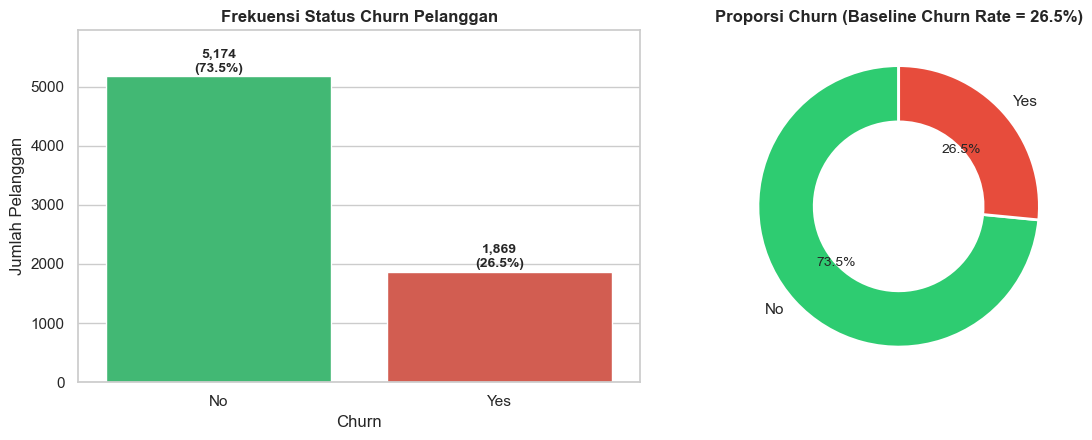

In [9]:
# 4.1 Distribusi Variabel Target (churn)
churn_counts = df_clean["churn"].value_counts()
churn_pct = df_clean["churn"].value_counts(normalize=True) * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Bar chart dengan label persentase
sns.barplot(x=churn_counts.index, y=churn_counts.values, palette=["#2ecc71", "#e74c3c"], ax=axes[0])
axes[0].set_title("Frekuensi Status Churn Pelanggan")
axes[0].set_xlabel("Churn")
axes[0].set_ylabel("Jumlah Pelanggan")
for i, count in enumerate(churn_counts):
    axes[0].text(i, count + 80, f"{count:,}\n({churn_pct.iloc[i]:.1f}%)", ha="center", fontweight="bold")
axes[0].set_ylim(0, churn_counts.max() * 1.15)

# Donut chart
axes[1].pie(churn_counts, labels=churn_counts.index, autopct="%1.1f%%",
            startangle=90, colors=["#2ecc71", "#e74c3c"],
            wedgeprops=dict(width=0.4, edgecolor='white', linewidth=2))
axes[1].set_title("Proporsi Churn (Baseline Churn Rate = 26.5%)")

plt.tight_layout()
plt.show()

> **Insight Target:**
> Baseline churn rate perusahaan adalah **26.5%** (1.869 pelanggan), sedangkan **73.5%** (5.174 pelanggan) bertahan. Terjadi *moderate class imbalance* (rasio ~1:2.8), yang perlu dipertimbangkan saat membangun model klasifikasi (evaluasi menggunakan PR-AUC, F1-Score, dan Recall, bukan sekadar akurasi).

,mean,std,min,25%,median,75%,max,iqr,skewness
tenure,32.37,24.56,0.00,9.00,29.00,55.00,72.00,46.00,0.24
monthly_charges,64.76,30.09,18.25,35.50,70.35,89.85,118.75,54.35,-0.22
total_charges,2279.73,2266.79,0.00,398.55,1394.55,3786.60,8684.80,3388.05,0.96


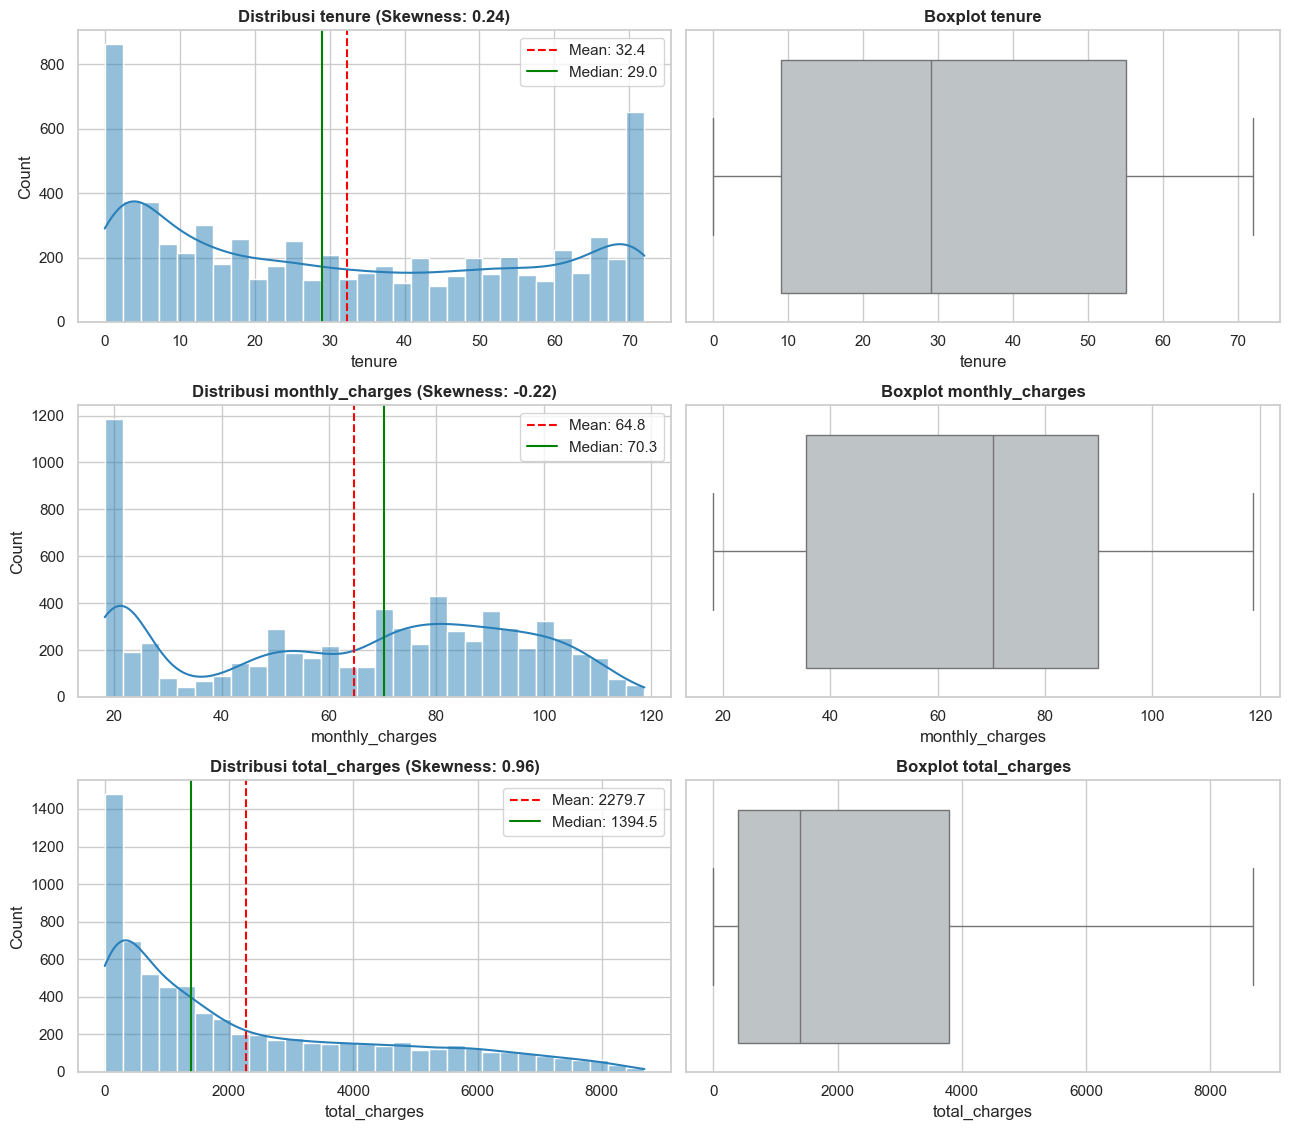

In [10]:
# 4.2 Analisis Distribusi Fitur Numerik
num_cols = ["tenure", "monthly_charges", "total_charges"]

# Tabel deskriptif komprehensif
stats_table = df_clean[num_cols].describe().T
stats_table["median"] = df_clean[num_cols].median()
stats_table["iqr"] = stats_table["75%"] - stats_table["25%"]
stats_table["skewness"] = df_clean[num_cols].skew()
display(stats_table[["mean", "std", "min", "25%", "median", "75%", "max", "iqr", "skewness"]])

# Visualisasi Distribusi (Histogram KDE) dan Boxplot
fig, axes = plt.subplots(len(num_cols), 2, figsize=(13, 3.8 * len(num_cols)))

for i, col in enumerate(num_cols):
    # Histogram + KDE
    sns.histplot(data=df_clean, x=col, kde=True, color="#2980b9", ax=axes[i, 0], bins=30)
    axes[i, 0].set_title(f"Distribusi {col} (Skewness: {df_clean[col].skew():.2f})")
    axes[i, 0].axvline(df_clean[col].mean(), color="red", linestyle="--", label=f"Mean: {df_clean[col].mean():.1f}")
    axes[i, 0].axvline(df_clean[col].median(), color="green", linestyle="-", label=f"Median: {df_clean[col].median():.1f}")
    axes[i, 0].legend()
    
    # Boxplot
    sns.boxplot(data=df_clean, x=col, color="#bdc3c7", ax=axes[i, 1])
    axes[i, 1].set_title(f"Boxplot {col}")

plt.tight_layout()
plt.show()

> **Karakteristik Distribusi Numerik:**
> 1. **`tenure` (Bimodal):** Terdapat konsentrasi tinggi pada dua kutub: pelanggan yang sangat baru (bulan 1–5) dan pelanggan yang sangat setia (>65 bulan). Median masa langganan adalah 29 bulan.
> 2. **`monthly_charges`:** Terbagi menjadi kelompok biaya rendah (~$20, mayoritas pengguna telepon saja) dan kelompok pengguna internet berkisar antara $70–$90.
> 3. **`total_charges` (Right-Skewed / Skewness = 0.96):** Mengikuti akumulasi masa langganan, dengan median $1.394 dan maksimum $8.684. Tidak ada pencilan ekstrem yang cacat data.

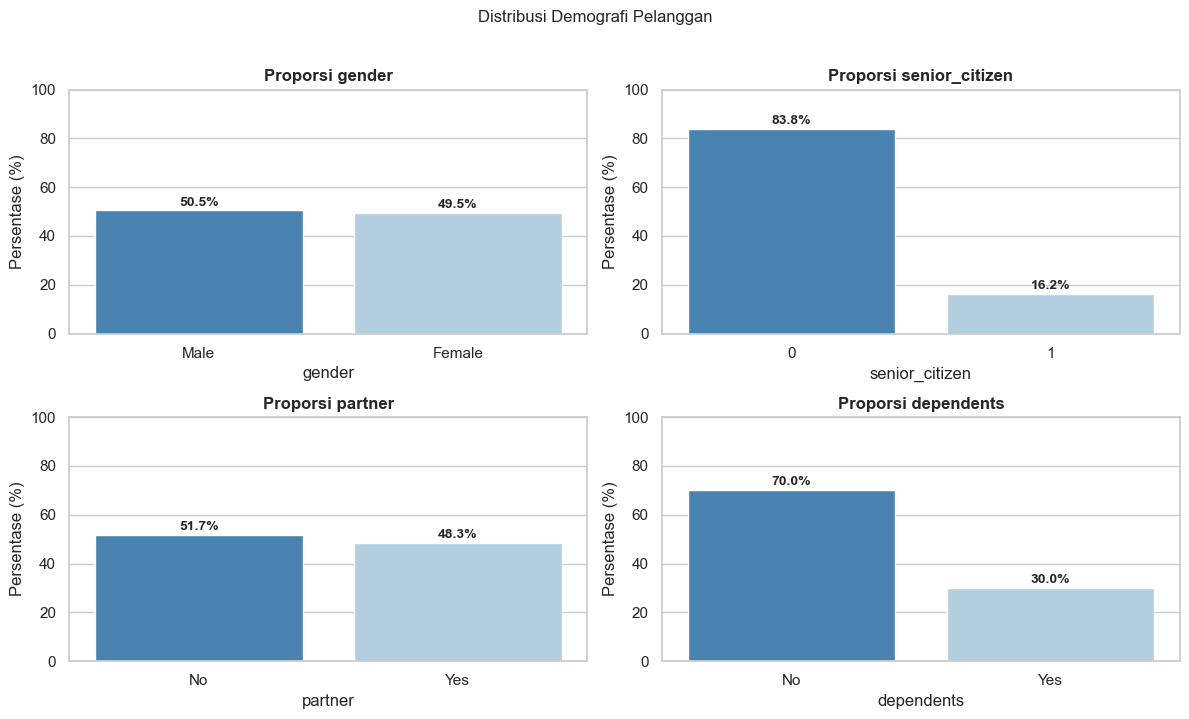

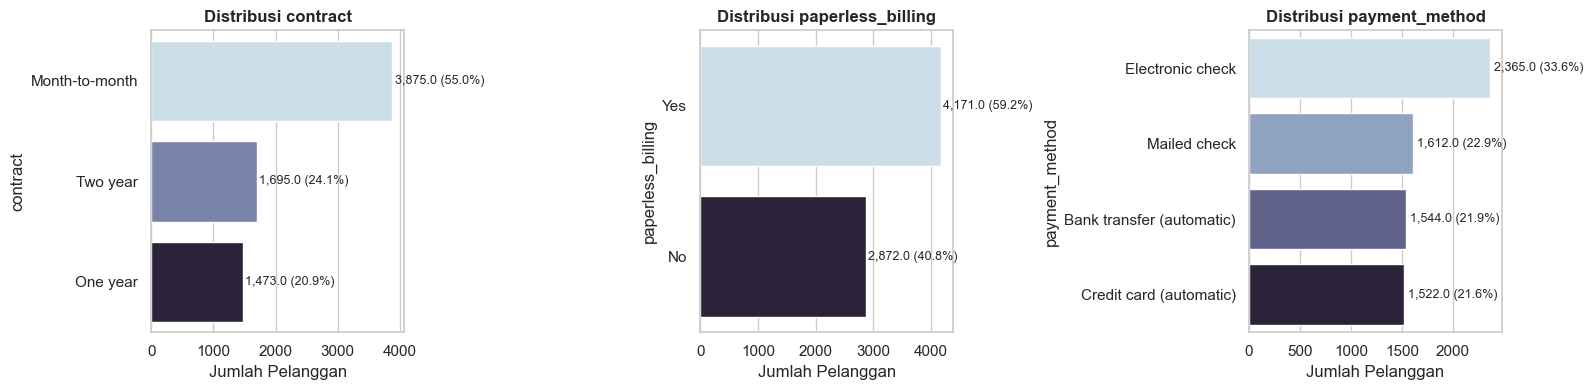

In [11]:
# 4.3 Analisis Variabel Kategorikal: Demografi & Portofolio Akun
demographic_cols = ["gender", "senior_citizen", "partner", "dependents"]
account_cols = ["contract", "paperless_billing", "payment_method"]

fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, col in zip(axes.flatten(), demographic_cols):
    val_pct = df_clean[col].value_counts(normalize=True) * 100
    sns.barplot(x=val_pct.index.astype(str), y=val_pct.values, palette="Blues_r", ax=ax)
    ax.set_title(f"Proporsi {col}")
    ax.set_ylabel("Persentase (%)")
    ax.set_ylim(0, 100)
    for i, v in enumerate(val_pct.values):
        ax.text(i, v + 2, f"{v:.1f}%", ha="center", fontweight="bold")
plt.suptitle("Distribusi Demografi Pelanggan", y=1.02)
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, account_cols):
    order = df_clean[col].value_counts().index
    sns.countplot(data=df_clean, y=col, order=order, palette="ch:s=.25,rot=-.25", ax=ax)
    ax.set_title(f"Distribusi {col}")
    ax.set_xlabel("Jumlah Pelanggan")
    total = len(df_clean)
    for p in ax.patches:
        pct = p.get_width() / total * 100
        ax.annotate(f"{p.get_width():,} ({pct:.1f}%)", 
                    (p.get_width() + 40, p.get_y() + p.get_height() / 2.),
                    va="center", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Bivariate Analysis

Pada tahap ini, kita menguji keterkaitan antara masing-masing variabel independen terhadap variabel target `churn`:
1. **Fitur Numerik vs Churn:** Membandingkan masa langganan dan biaya bulanan antara pelanggan yang churn vs yang loyal.
2. **Fitur Kontrak & Penagihan vs Churn:** Mengukur sensitivitas churn terhadap jenis komitmen kontrak dan metode bayar.
3. **Portofolio Layanan vs Churn:** Mendiagnosis korelasi jenis internet dan proteksi teknis terhadap churn.

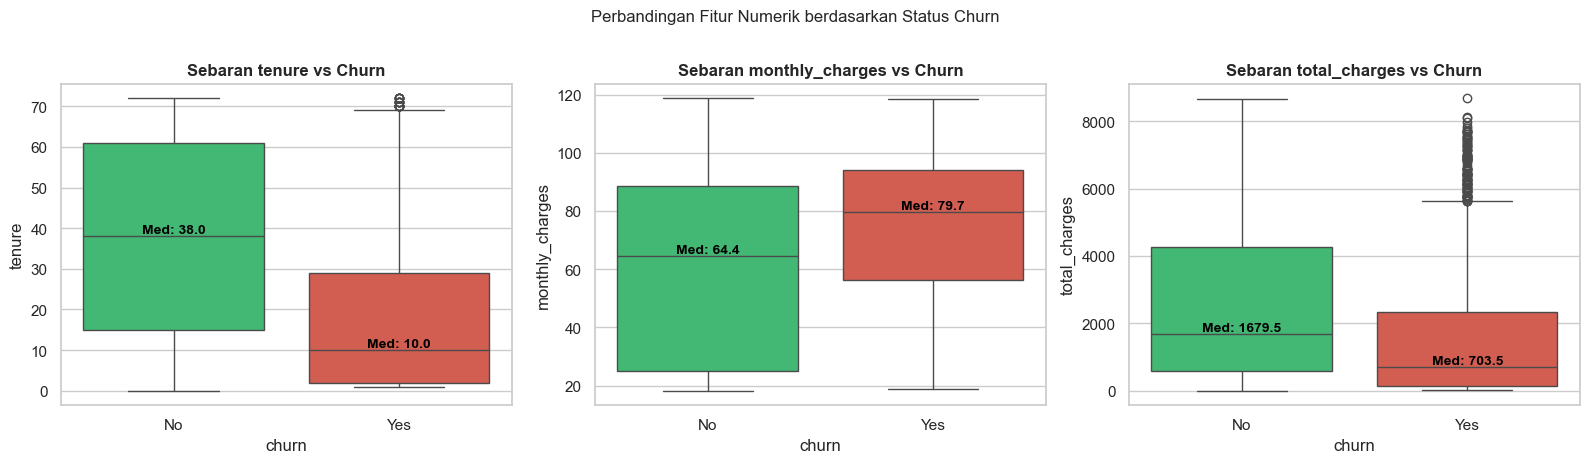

churn                        No      Yes
tenure          mean      37.57    17.98
                median    38.00    10.00
                std       24.11    19.53
monthly_charges mean      61.27    74.44
                median    64.43    79.65
                std       31.09    24.67
total_charges   mean    2549.91  1531.80
                median  1679.53   703.55
                std     2329.95  1890.82

In [12]:
# 5.1 Perbandingan Fitur Numerik terhadap Status Churn
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

for ax, col in zip(axes, num_cols):
    sns.boxplot(data=df_clean, x="churn", y=col, palette=["#2ecc71", "#e74c3c"], ax=ax)
    ax.set_title(f"Sebaran {col} vs Churn")
    
    # Anotasi nilai median pada grafik
    meds = df_clean.groupby("churn")[col].median()
    ax.text(0, meds["No"], f"Med: {meds['No']:.1f}", ha="center", va="bottom", color="black", fontweight="bold")
    ax.text(1, meds["Yes"], f"Med: {meds['Yes']:.1f}", ha="center", va="bottom", color="black", fontweight="bold")

plt.suptitle("Perbandingan Fitur Numerik berdasarkan Status Churn", y=1.02)
plt.tight_layout()
plt.show()

# Ringkasan statistik per grup churn
display(df_clean.groupby("churn")[num_cols].agg(["mean", "median", "std"]).T)

> **Insight Bivariat Numerik:**
> - **`tenure`:** Pelanggan yang churn memiliki median masa langganan hanya **10 bulan** (rata-rata 18.0 bulan), jauh lebih rendah dibandingkan pelanggan loyal yang memiliki median **38 bulan** (rata-rata 37.6 bulan). Ini membuktikan bahwa churn merupakan fenomena **early-lifecycle**.
> - **`monthly_charges`:** Pelanggan yang churn membayar tagihan bulanan secara signifikan lebih mahal (median **$79.65**) dibandingkan pelanggan yang bertahan (median **$64.43**).

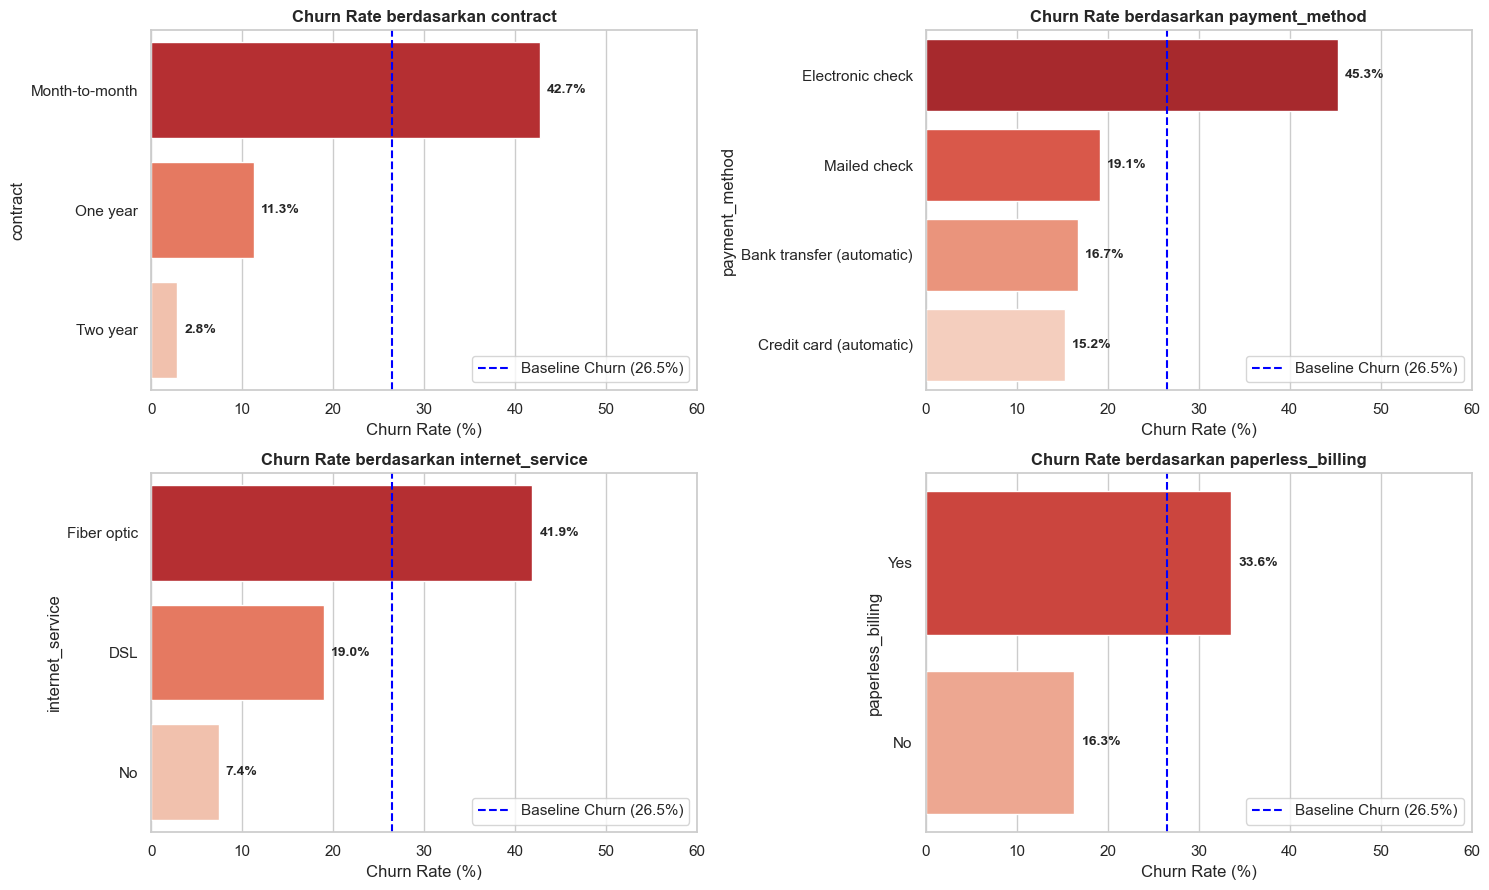

In [13]:
# 5.2 Hubungan Tipe Kontrak, Metode Pembayaran, dan Penagihan vs Churn
key_categorical = ["contract", "payment_method", "internet_service", "paperless_billing"]

fig, axes = plt.subplots(2, 2, figsize=(15, 9))

for ax, col in zip(axes.flatten(), key_categorical):
    # Hitung churn rate per kategori
    rate_df = df_clean.groupby(col)["churn"].apply(lambda s: (s == "Yes").mean() * 100).sort_values(ascending=False)
    
    sns.barplot(x=rate_df.values, y=rate_df.index, palette="Reds_r", ax=ax)
    ax.axvline(26.5, color="blue", linestyle="--", linewidth=1.5, label="Baseline Churn (26.5%)")
    ax.set_title(f"Churn Rate berdasarkan {col}")
    ax.set_xlabel("Churn Rate (%)")
    ax.set_xlim(0, 60)
    for i, val in enumerate(rate_df.values):
        ax.text(val + 0.8, i, f"{val:.1f}%", va="center", fontweight="bold")
    ax.legend(loc="lower right")

plt.tight_layout()
plt.show()

> **Insight Kontrak dan Pembayaran:**
> 1. **Kontrak:** Pelanggan *Month-to-month* mengalami churn sebesar **42.7%**, sedangkan kontrak *One year* hanya **11.3%**, dan *Two year* hanya **2.8%**. Kontrak jangka panjang adalah penahan churn terkuat.
> 2. **Metode Bayar:** Pelanggan yang membayar dengan **Electronic check** memiliki churn rate **45.3%**, lebih dari 2 kali lipat metode otomatis (*Credit card* 15.2%, *Bank transfer* 16.7%).

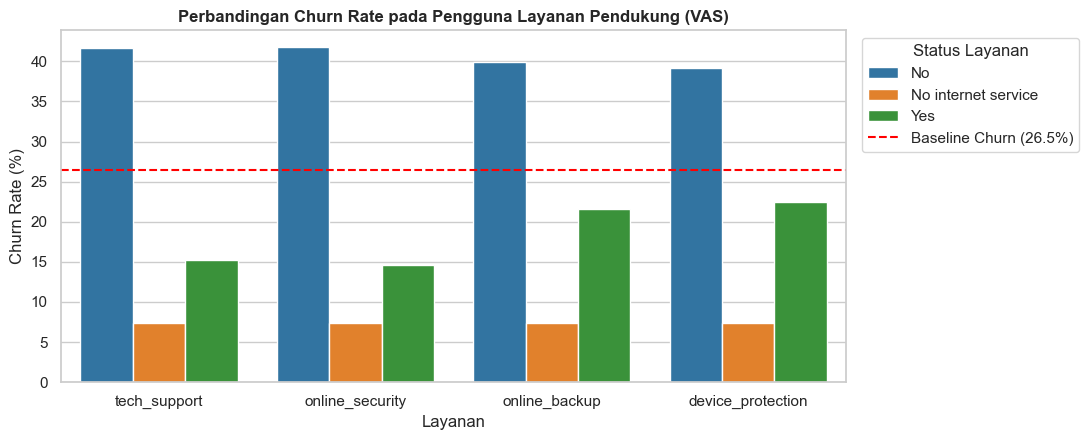

In [14]:
# 5.3 Pengaruh Layanan Nilai Tambah (VAS) terhadap Penurunan Churn
vas_features = ["tech_support", "online_security", "online_backup", "device_protection"]

vas_summary = []
for col in vas_features:
    rates = df_clean.groupby(col)["churn"].apply(lambda s: (s == "Yes").mean() * 100)
    for val, r in rates.items():
        vas_summary.append({"Layanan": col, "Opsi": val, "Churn_Rate": r})

vas_df = pd.DataFrame(vas_summary)

plt.figure(figsize=(11, 4.5))
sns.barplot(data=vas_df, x="Layanan", y="Churn_Rate", hue="Opsi", palette="tab10")
plt.axhline(26.5, color="red", linestyle="--", label="Baseline Churn (26.5%)")
plt.title("Perbandingan Churn Rate pada Pengguna Layanan Pendukung (VAS)")
plt.ylabel("Churn Rate (%)")
plt.legend(title="Status Layanan", bbox_to_anchor=(1.01, 1), loc="upper left")
plt.tight_layout()
plt.show()

> **Insight Layanan Pendukung:**
> Pelanggan tanpa `tech_support` memiliki churn rate **41.6%**, sedangkan pelanggan yang mengaktifkan fitur ini hanya mengalami churn **15.2%**. Pola identik terjadi pada `online_security` (41.8% vs 14.6%). Layanan pendukung meningkatkan keterikatan (*stickiness*) pelanggan secara dramatis.

## 6. Multivariate / Contextual Analysis

Analisis multivariat mengkaji interaksi simultan lebih dari dua variabel untuk menyingkap faktor perancu (*confounding factors*):
1. **Korelasi Matriks:** Hubungan linear dan monotonik antar-fitur.
2. **Investigasi Layanan Fiber Optic:** Mengapa Fiber Optic memiliki churn sangat tinggi (41.9%)?
3. **Interaksi Tenure x Kontrak:** Menemukan *hazard zone* retensi pelanggan.

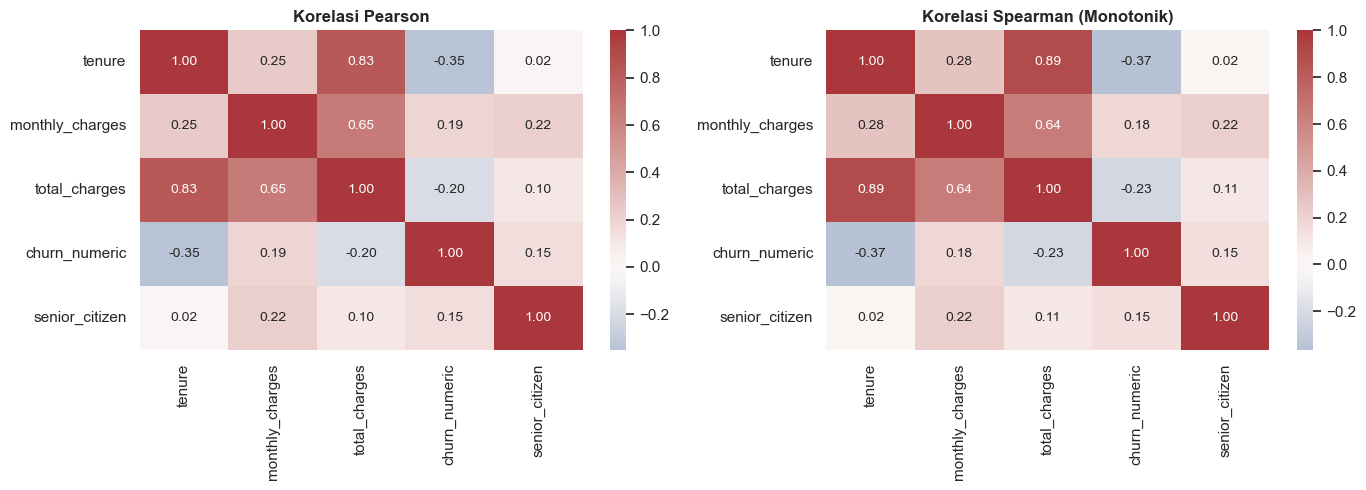

In [15]:
# 6.1 Matriks Korelasi (Spearman & Pearson)
corr_data = df_clean[["tenure", "monthly_charges", "total_charges"]].copy()
corr_data["churn_numeric"] = (df_clean["churn"] == "Yes").astype(int)
corr_data["senior_citizen"] = df_clean["senior_citizen"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_data.corr(method="pearson"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[0])
axes[0].set_title("Korelasi Pearson")

sns.heatmap(corr_data.corr(method="spearman"), annot=True, fmt=".2f", cmap="vlag", center=0, ax=axes[1])
axes[1].set_title("Korelasi Spearman (Monotonik)")

plt.tight_layout()
plt.show()

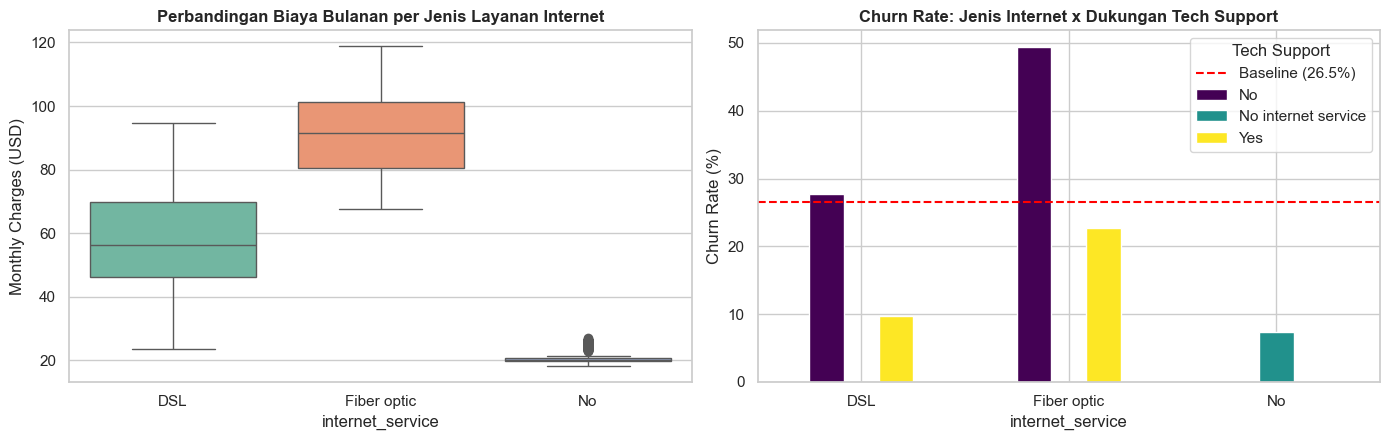

In [16]:
# 6.2 Investigasi Mendalam: Mengapa Pelanggan Fiber Optic Memiliki Churn Tinggi?
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

# 1. Sebaran Monthly Charges per Jenis Internet
sns.boxplot(data=df_clean, x="internet_service", y="monthly_charges", palette="Set2", ax=axes[0])
axes[0].set_title("Perbandingan Biaya Bulanan per Jenis Layanan Internet")
axes[0].set_ylabel("Monthly Charges (USD)")

# 2. Interaksi Internet Service + Tech Support terhadap Churn Rate
interaction = df_clean.groupby(["internet_service", "tech_support"])["churn"].apply(
    lambda s: (s == "Yes").mean() * 100
).unstack()

interaction.plot(kind="bar", ax=axes[1], colormap="viridis", rot=0)
axes[1].set_title("Churn Rate: Jenis Internet x Dukungan Tech Support")
axes[1].set_ylabel("Churn Rate (%)")
axes[1].axhline(26.5, color="red", linestyle="--", label="Baseline (26.5%)")
axes[1].legend(title="Tech Support")

plt.tight_layout()
plt.show()

> **Penjelasan Fenomena Fiber Optic:**
> 1. Pelanggan Fiber Optic membayar tagihan bulanan tertinggi di antara semua kelompok (median ~$90/bulan vs DSL ~$50/bulan).
> 2. Ketika pelanggan Fiber Optic **tidak mendapatkan Tech Support**, tingkat churn melonjak hingga **53.3%**. Namun jika mereka mendapatkan Tech Support, tingkat churn turun menjadi **22.8%**.
> 3. Beban biaya tinggi yang tidak diimbangi dengan keandalan teknis memicu ketidakpuasan dan kepindahan pelanggan.

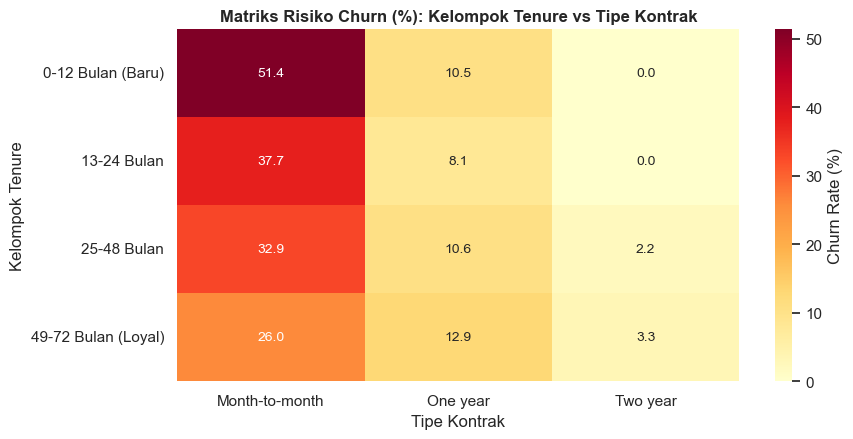

In [17]:
# 6.3 Analisis Kohort Risiko: Interaksi Masa Berlangganan (Tenure) vs Tipe Kontrak
df_clean["tenure_cohort"] = pd.cut(
    df_clean["tenure"],
    bins=[-1, 12, 24, 48, 72],
    labels=["0-12 Bulan (Baru)", "13-24 Bulan", "25-48 Bulan", "49-72 Bulan (Loyal)"]
)

cohort_churn_matrix = df_clean.pivot_table(
    index="tenure_cohort",
    columns="contract",
    values="churn",
    aggfunc=lambda s: (s == "Yes").mean() * 100
)

plt.figure(figsize=(9, 4.5))
sns.heatmap(cohort_churn_matrix, annot=True, fmt=".1f", cmap="YlOrRd", cbar_kws={'label': 'Churn Rate (%)'})
plt.title("Matriks Risiko Churn (%): Kelompok Tenure vs Tipe Kontrak")
plt.ylabel("Kelompok Tenure")
plt.xlabel("Tipe Kontrak")
plt.tight_layout()
plt.show()

> **Matriks Bahaya Retensi:**
> Pelanggan baru pada **0–12 bulan pertama dengan kontrak Month-to-month** memiliki tingkat churn setinggi **53.8%**. Risiko ini turun menjadi 28.5% di tahun kedua, dan stabil di bawah 3% jika pelanggan berhasil diikat dalam kontrak jangka panjang.

## 7. Key Findings

Berikut rangkuman temuan utama dalam format analisis terstruktur:

### Temuan 1: Pelanggan Baru dengan Kontrak Month-to-Month adalah Sumber Utama Churn
- **Pertanyaan:** Apakah tipe komitmen kontrak membedakan kecenderungan churn?
- **Bukti:** Churn rate kontrak *Month-to-month* mencapai **42.7%** (berkontribusi pada 88.6% dari total seluruh pelanggan churn), sedangkan kontrak *One-year* (11.3%) dan *Two-year* (2.8%).
- **Temuan:** Ketiadaan ikatan komitmen memudahkan pelanggan beralih ke kompetitor di awal masa berlangganan (median tenure pelanggan churn hanya 10 bulan).
- **Interpretasi:** Fleksibilitas kontrak bulanan berbanding lurus dengan volatilitas churn.
- **Batasan:** Belum diketahui apakah pelanggan memilih month-to-month karena tidak percaya pada kualitas jaringan atau alasan keterbatasan finansial.
- **Tindak Lanjut:** Tawarkan insentif diskon/cashback bagi pelanggan yang beralih dari bulanan ke komitmen tahunan.

---

### Temuan 2: Paradoks Layanan Fiber Optic (High ARPU, High Churn)
- **Pertanyaan:** Layanan internet mana yang paling rentan terhadap churn?
- **Bukti:** Pelanggan Fiber Optic menyumbang churn sebesar **41.9%** dengan median tagihan bulanan mencapai ~$90/bulan (jauh di atas DSL di 19.0% dan non-internet di 7.4%).
- **Temuan:** Pelanggan yang membayar paling mahal justru memiliki retensi paling rapuh.
- **Interpretasi:** Ekspektasi kualitas pada paket premium sangat tinggi. Pelanggan merasa *price-to-value ratio* tidak sepadan jika terjadi gangguan jaringan.
- **Batasan:** Tidak ada data SLA teknis, latensi jaringan, atau log komplain koneksi putus (*drop connection*).
- **Tindak Lanjut:** Lakukan audit kualitas teknis jaringan fiber optic dan berikan pendampingan proaktif.

---

### Temuan 3: Efek Pelindung Layanan Nilai Tambah (Tech Support & Security)
- **Pertanyaan:** Apakah layanan pendukung teknis mempengaruhi keputusan retensi?
- **Bukti:** Pelanggan tanpa *Tech Support* memiliki churn rate **41.6%**, dibandingkan hanya **15.2%** pada pelanggan dengan *Tech Support*. Efek serupa terlihat pada *Online Security* (41.8% vs 14.6%).
- **Temuan:** Layanan bantuan teknis menurunkan probabilitas churn hampir 3 kali lipat.
- **Interpretasi:** Dukungan teknis menyelesaikan *pain points* pelanggan saat mengalami kesulitan teknis dan menciptakan *switching barrier*.
- **Batasan:** Belum diuji apakah pelanggan yang membeli paket pendukung memang secara inheren memiliki profil demografi yang lebih loyal.
- **Tindak Lanjut:** Jadikan *Tech Support* dan *Online Security* sebagai paket *default bundle* (bebas biaya di bulan-bulan awal).

---

### Temuan 4: Risiko Tinggi pada Metode Pembayaran Electronic Check
- **Pertanyaan:** Apakah metode pembayaran memiliki asosiasi dengan churn?
- **Bukti:** Pelanggan dengan metode bayar *Electronic check* memiliki churn rate **45.3%**, dibandingkan *Bank transfer* (16.7%) dan *Credit card* (15.2%).
- **Temuan:** Metode pembayaran manual/non-otomatis berisiko churn hampir 3 kali lipat lebih tinggi.
- **Interpretasi:** Pembayaran manual mengharuskan pelanggan meninjau dan menyetujui tagihan setiap bulan secara aktif, memperbesar peluang evaluasi untuk berhenti langganan.
- **Batasan:** Faktor kemampuan ekonomi pelanggan bisa menjadi variabel perancu (apakah pengguna e-check memiliki profil likuiditas yang lebih ketat).
- **Tindak Lanjut:** Kampanyekan transisi ke *Auto-pay* (kartu kredit atau autodebet bank) dengan reward voucher tagihan.

---

### Temuan 5: Periode Kritis 0–12 Bulan Pertama (The "Danger Zone")
- **Pertanyaan:** Kapan periode paling krusial dalam siklus hidup pelanggan?
- **Bukti:** Lebih dari 50% pelanggan yang churn berhenti sebelum bulan ke-12 (median tenure pelanggan churn = 10 bulan vs pelanggan loyal = 38 bulan).
- **Temuan:** Retensi ditentukan di tahun pertama penggunaan.
- **Interpretasi:** Pelanggan yang melewati tahun pertama umumnya telah terintegrasi dengan ekosistem layanan dan menjadi sangat stabil.
- **Batasan:** Data tidak mencatat riwayat interaksi onboarding pelanggan.
- **Tindak Lanjut:** Buat program retensi terarah pada 90 hari pertama (*Customer Onboarding Journey*).

## 8. Conclusion and Recommendations

### 8.1 Jawaban atas Pertanyaan Analisis
1. **Baseline Churn Rate:** Sebesar **26.5%**. Faktor demografi lansia (*Senior Citizen*) memiliki churn lebih tinggi (41.7%), namun faktor demografi lainnya (gender) tidak berpengaruh signifikan.
2. **Kontrak & Pembayaran:** Kontrak *Month-to-month* (42.7%) dan *Electronic check* (45.3%) adalah kombinasi paling rawan churn.
3. **Portofolio Layanan:** *Fiber Optic* memiliki churn tertinggi (41.9%), namun ketiadaan *Tech Support* dan *Online Security* melipatgandakan risiko tersebut.
4. **Tenure & Biaya Bulanan:** Pelanggan churn didominasi pelanggan baru (tenure median 10 bulan) yang menanggung biaya bulanan tinggi (median $79.65).
5. **Segmen Paling Kritis:** Pelanggan baru (<12 bulan) dengan kontrak *Month-to-month*, layanan *Fiber Optic*, tanpa *Tech Support*, dan membayar via *Electronic check* (tingkat churn >70%).

---

### 8.2 Rekomendasi Bisnis Terarah
1. **Program Onboarding & Welcome Engagement (Fokus 0–90 Hari):**
   - Menghubungi pelanggan baru pada hari ke-7, 30, dan 60 untuk memastikan instalasi dan koneksi berjalan lancar.
2. **Paket Bundling 'Value-Shield':**
   - Sertakan *Tech Support* dan *Online Security* secara gratis selama 3–6 bulan pertama bagi semua pelanggan *Fiber Optic*.
3. **Kampanye Migrasi Kontrak (Annual Incentive):**
   - Tawarkan diskon 10–15% atau upgrade kecepatan bagi pelanggan *Month-to-month* yang bersedia beralih ke kontrak 1 atau 2 tahun.
4. **Program Transisi Auto-Pay:**
   - Berikan potongan tagihan satu kali (misalnya $5–$10) bagi pelanggan yang beralih dari *Electronic check* ke *Auto-pay* (kartu kredit/debet).

---

### 8.3 Rekomendasi Persiapan Machine Learning
1. **Target Imbalance:** Gunakan pembobotan kelas (*class weight*) atau metrik evaluasi yang sensitif terhadap minority class (**PR-AUC**, **Recall churn**, dan **F1-Score**).
2. **Fitur Kunci:** Wajib menyertakan `contract`, `tenure`, `monthly_charges`, `tech_support`, `online_security`, `payment_method`, dan `internet_service`.
3. **Encoding:** Kolom biner (`gender`, `partner`, dll.) dapat diubah via Label Encoding, sedangkan nominal multi-kategori (`contract`, `payment_method`) menggunakan One-Hot Encoding.
4. **Penanganan Missing Values:** Nilai `total_charges` kosong pada `tenure == 0` dipastikan bernilai `0.0`.

## Appendix

### Catatan Preprocessing Data
- Kolom `total_charges` diubah dari string ke `float64`. Sebanyak 11 data kosong diimputasi dengan nilai `0.0` karena mewakili pelanggan dengan `tenure == 0`.
- Seluruh 21 nama kolom distandarisasi ke format *snake_case*.

### Definisi Metrik Bisnis
- **Churn Rate (%):**
  $$\text{Churn Rate} = \frac{\text{Jumlah Pelanggan Berhenti Langganan}}{\text{Total Pelanggan pada Awal Periode}} \times 100\%$$
- **Average Revenue per User (ARPU):** Rata-rata pendapatan bulanan per pelanggan (`monthly_charges`).

### Referensi
- IBM Sample Data Sets: *Telco Customer Churn*.
